In [25]:
# AI-Based Predictive Maintenance System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [26]:
# Load the dataset

df = pd.read_csv("dataset/ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [27]:
# Dataset information

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Statistics:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [28]:
# Machine Failure Distribution

failure_counts = df["Machine failure"].value_counts()

print("Machine Failure Distribution:")
print(failure_counts)

print("\nFailure Percentage:")
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


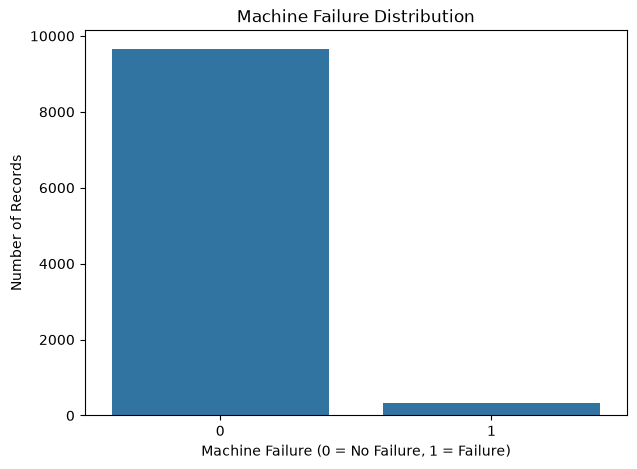

In [29]:
# Visualize Machine Failure Distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")

plt.show()

In [30]:
# Select important sensor features

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print("Selected Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Selected Features:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  
1         46.3                3  
2         49.4                5  
3         39.5                7  
4         40.0                9  

Target Variable:
0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

Feature Shape: (10000, 5)
Target Shape: (10000,)


In [31]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 5)
Testing Features: (2000, 5)

Training Target: (8000,)
Testing Target: (2000,)


In [32]:
# Train the Random Forest model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


In [33]:
# Predict machine failures

y_pred = rf_model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 Actual Values:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


In [34]:
# Evaluate Random Forest Model

from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Model Accuracy: 98.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.73      0.72      0.73        68

    accuracy                           0.98      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.98      0.98      0.98      2000



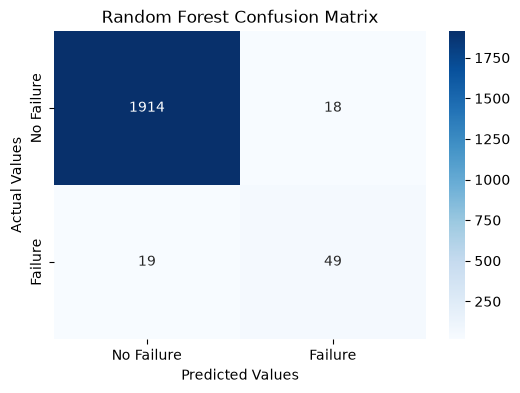

In [35]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

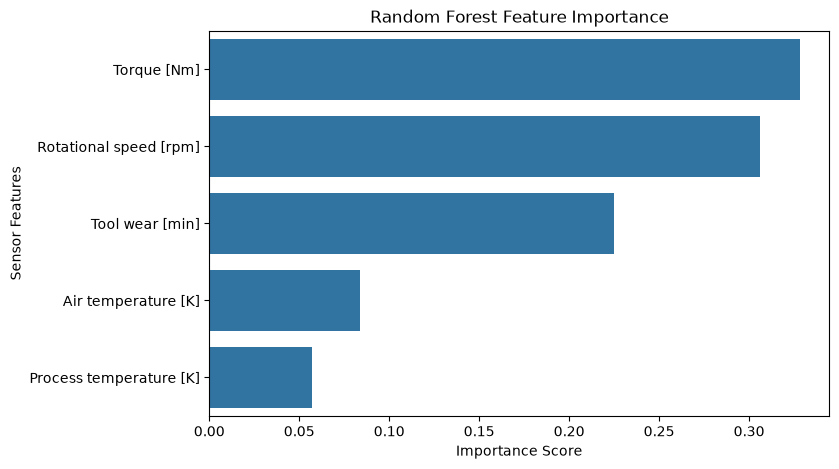

Torque [Nm]                0.328165
Rotational speed [rpm]     0.306219
Tool wear [min]            0.224945
Air temperature [K]        0.083586
Process temperature [K]    0.057085
dtype: float64


In [36]:
# Random Forest Feature Importance

importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Sensor Features")

plt.show()

print(importance)

In [37]:
# Train Decision Tree Model

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Model trained successfully!")

Decision Tree Model trained successfully!


In [38]:
# Evaluate Decision Tree Model

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Model Accuracy:", dt_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Model Accuracy: 92.75 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1932
           1       0.31      0.91      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.92      0.71      2000
weighted avg       0.97      0.93      0.94      2000



In [39]:
# Train Logistic Regression Model

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Model trained successfully!")

Logistic Regression Model trained successfully!


In [40]:
# Evaluate Logistic Regression Model

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Model Accuracy:", lr_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

Logistic Regression Model Accuracy: 82.1 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [41]:
# Compare Machine Learning Models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        lr_accuracy * 100,
        dt_accuracy * 100,
        accuracy * 100
    ]
})

model_comparison = model_comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
)

model_comparison

,Model,Accuracy (%)
2,Random Forest,98.15
1,Decision Tree,92.75
0,Logistic Regression,82.10


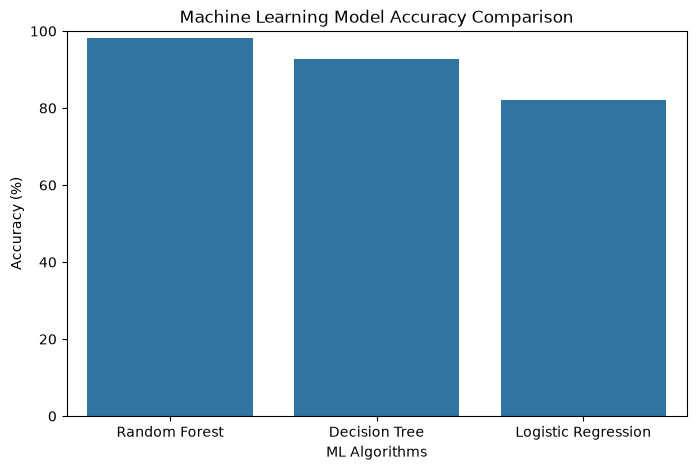

In [42]:
# Visual Comparison of Model Accuracy

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("ML Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [43]:
# Save Model Comparison Results

model_comparison.to_csv("model_comparison_notebook.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [44]:
# Save the Random Forest Model

import joblib

joblib.dump(rf_model, "random_forest_model_notebook.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


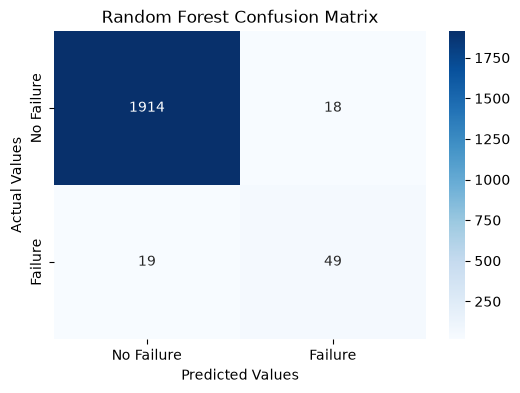

Confusion matrix image saved successfully!


In [45]:
# Save Random Forest Confusion Matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.savefig("random_forest_confusion_matrix_notebook.png", dpi=300, bbox_inches="tight")

plt.show()

print("Confusion matrix image saved successfully!")

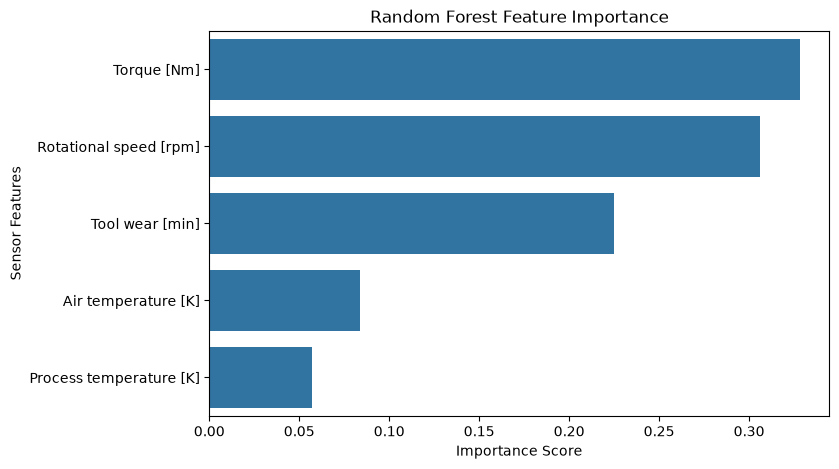

Feature importance graph saved successfully!


In [46]:
# Save Feature Importance Graph

plt.figure(figsize=(8, 5))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Sensor Features")

plt.savefig(
    "feature_importance_notebook.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance graph saved successfully!")

## Conclusion

In this notebook, an AI-Based Predictive Maintenance System was developed using the AI4I 2020 dataset.

The dataset was explored and analysed to understand machine failure patterns. Three machine learning algorithms — Logistic Regression, Decision Tree, and Random Forest — were trained and evaluated.

Their performance was compared using accuracy and classification metrics. The Random Forest model was selected for the project application.

The analysis demonstrates how machine learning can help identify potential industrial machine failures and support predictive maintenance.